In [9]:
import skfuzzy as fuzz
import numpy as np
import cv2
import matplotlib.pyplot as plt
from skfuzzy import control as ctrl
import matplotlib.pyplot as plt

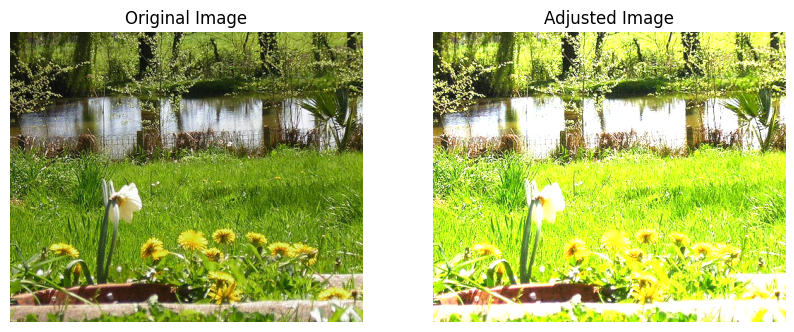

In [14]:
def fuzzy_brightness(image):
    gray_image = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)
    average_brightness = np.mean(gray_image)

    x_brightness = np.arange(0, 256, 1)
    low = fuzz.trimf(x_brightness, [0, 0, 128])
    medium = fuzz.trimf(x_brightness, [64, 128, 192])
    high = fuzz.trimf(x_brightness, [128, 256, 256])

    low_membership = fuzz.interp_membership(x_brightness, low, average_brightness)
    medium_membership = fuzz.interp_membership(x_brightness, medium, average_brightness)
    high_membership = fuzz.interp_membership(x_brightness, high, average_brightness)

    
    adjustment_factor = low_membership * 3 + medium_membership * 2 + high_membership * 0.3
    adjusted_image = image * adjustment_factor
    adjusted_image = np.clip(adjusted_image, 0, 255).astype(np.uint8)

    return adjusted_image

image = cv2.imread(r'flowers/dandelion/9818247_e2eac18894.jpg')

adjusted_image = fuzzy_brightness(image)

image_rgb = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)
adjusted_image_rgb = cv2.cvtColor(adjusted_image, cv2.COLOR_BGR2RGB)

plt.figure(figsize=(10, 5))

plt.subplot(1, 2, 1)
plt.imshow(image_rgb)
plt.title('Original Image')
plt.axis('off')

# Adjusted Image
plt.subplot(1, 2, 2)
plt.imshow(adjusted_image_rgb)
plt.title('Adjusted Image')
plt.axis('off')

# Show the plot
plt.show()


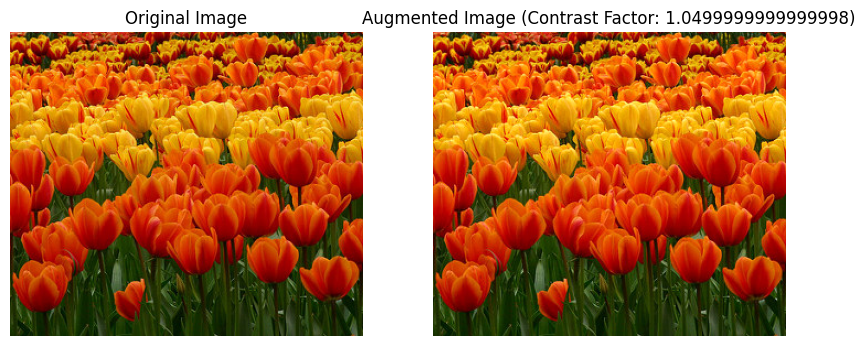

In [21]:
def apply_contrast(image, contrast_factor):
    return cv2.convertScaleAbs(image, alpha=contrast_factor, beta=0)

def calculate_image_contrast(image):
    gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)
    contrast = np.max(gray) - np.min(gray)
    return contrast

def fuzzy_contrast_adjustment(image):
    contrast = calculate_image_contrast(image)
    x = np.arange(0, 256, 1)
    
    low = fuzz.trapmf(x, [0, 0, 50, 100])
    medium = fuzz.trimf(x, [50, 128, 200])
    high = fuzz.trapmf(x, [150, 200, 255, 255])
    
    contrast_factor = 1.5*(2*fuzz.interp_membership(x, low, contrast) + 0.5 *fuzz.interp_membership(x, medium, contrast) + 0.7* fuzz.interp_membership(x, high, contrast))
    
    return contrast_factor

# Read image
image = cv2.imread(r"flowers/tulip/11746548_26b3256922_n.jpg")

# Determine the contrast factor using fuzzy logic
contrast_factor = fuzzy_contrast_adjustment(image)

# Apply contrast adjustment
augmented_image = apply_contrast(image, contrast_factor)

# Display the original and augmented images
plt.figure(figsize=(10,5))
plt.subplot(1, 2, 1)
plt.imshow(cv2.cvtColor(image, cv2.COLOR_BGR2RGB))
plt.title("Original Image")
plt.axis('off')

plt.subplot(1, 2, 2)
plt.imshow(cv2.cvtColor(augmented_image, cv2.COLOR_BGR2RGB))
plt.title(f"Augmented Image (Contrast Factor: {contrast_factor})")
plt.axis('off')

plt.show()


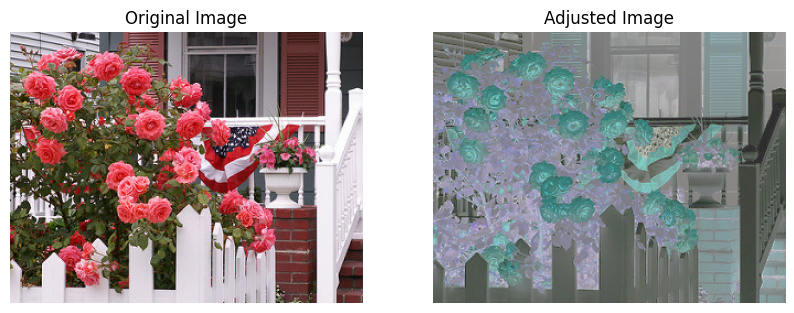

In [16]:
import numpy as np
import cv2
import skfuzzy as fuzz


brightness = ctrl.Antecedent(np.arange(0, 256, 1), 'brightness')
adjustment = ctrl.Consequent(np.arange(0, 256, 1), 'adjustment')

brightness['dark'] = fuzz.trimf(brightness.universe, [0, 0, 128])
brightness['medium'] = fuzz.trimf(brightness.universe, [0, 128, 255])
brightness['bright'] = fuzz.trimf(brightness.universe, [128, 255, 255])

adjustment['low'] = fuzz.trimf(adjustment.universe, [0, 0, 128])
adjustment['medium'] = fuzz.trimf(adjustment.universe, [0, 128, 255])
adjustment['high'] = fuzz.trimf(adjustment.universe, [128, 255, 255])

rule1 = ctrl.Rule(brightness['dark'], adjustment['high'])
rule2 = ctrl.Rule(brightness['medium'], adjustment['medium'])
rule3 = ctrl.Rule(brightness['bright'], adjustment['low'])

brightness_ctrl = ctrl.ControlSystem([rule1, rule2, rule3])
brightness_sim = ctrl.ControlSystemSimulation(brightness_ctrl)

def fuzzy_brightness(image):
    adjusted_image = np.zeros_like(image)
    for i in range(image.shape[0]):
        for j in range(image.shape[1]):
            for k in range(image.shape[2]):
                brightness_sim.input['brightness'] = image[i, j, k]
                brightness_sim.compute()
                adjusted_image[i, j, k] = brightness_sim.output['adjustment']
    
    return adjusted_image

image = cv2.imread(r'flowers/rose/159079265_d77a9ac920_n.jpg')

adjusted_image = fuzzy_brightness(image)

image_rgb = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)
adjusted_image_rgb = cv2.cvtColor(adjusted_image, cv2.COLOR_BGR2RGB)


plt.figure(figsize=(10, 5))

plt.subplot(1, 2, 1)
plt.imshow(image_rgb)
plt.title('Original Image')
plt.axis('off')

plt.subplot(1, 2, 2)
plt.imshow(adjusted_image_rgb)
plt.title('Adjusted Image')
plt.axis('off')

plt.show()